# 1 · Which signal should tell a data scientist to retrain?

**The situation:** a model is in production. The world it learned from may change. A monitoring rule
watches something and, when it crosses a line, pages a data scientist to retrain. Retraining costs
time and compute; *not* retraining costs bad predictions. What should the rule watch?

**The test bench:** simulated data streams (think: one batch per week, 500 rows each) where we decide
exactly when and how the world changes, so we know the right answer:

| Scenario | What changes | Should we retrain? |
|---|---|---|
| none | nothing | no |
| covariate_harmless | the inputs move, but where the model already works | no |
| covariate_harmful | the inputs move where the model never learned | yes |
| concept_sudden | the *meaning* changes: same inputs, different right answer | yes |
| concept_gradual | the same, phased in over 20 batches | yes |
| concept_complex | the relationship becomes much more intricate | yes |

The change starts at batch 40 of 80. The model (gradient-boosted trees, tuned at the start) trains on
batches 0-19. True answers ("labels") come back 2 batches late, as they do in real life.

## Key terms

Plain-language definitions of the terms this notebook uses; the full sources are listed under References at the end.

- **Drift:** The data a model sees in production stops looking like the data it was trained on, so its predictions can get worse over time. An umbrella word for the two kinds below. *(See: Treveil 2020, McMahon 2023, Gama 2014.)*
- **Input drift (covariate shift, data drift):** The *inputs* change (more suburban deliveries, hotter summers) but the rule linking inputs to the right answer stays the same. Harmless if the model has already seen inputs like the new ones; harmful if they are new territory. Terminology varies between books: McMahon uses "covariate drift" for what is called concept drift below; this project follows Moreno-Torres et al. *(See: Moreno-Torres 2012, Quiñonero-Candela 2009, Treveil 2020.)*
- **Concept drift:** The *meaning* changes: the same inputs now lead to a different right answer (a new road makes the same distance quicker). Input monitors cannot see it, because the inputs look unchanged. It can be sudden or gradual. *(See: Kubat 2017, Gama 2014, Lu 2019, McMahon 2023.)*
- **Labels and label delay:** A label is the true answer for a prediction (the actual delivery time, the actual demand). In production it arrives later than the prediction; label delay is how much later. Error-based monitors must wait for it; input monitors don't. *(See: Treveil 2020, Kubat 2017.)*
- **Trigger and threshold:** A rule that watches one score each batch and pages someone to retrain when the score crosses a threshold. Lower threshold = more sensitive = more false alarms. *(See: McMahon 2023, Ameisen 2020.)*
- **False-alarm rate and calibration:** How often a trigger fires when nothing has changed. Here every trigger's threshold is set (calibrated) so they all fire about once per 300 drift-free batches; otherwise a more sensitive trigger would look better just because it fires more. *(See: Basseville 1993.)*
- **Population Stability Index (PSI):** Splits a feature's training values into 10 equal-count bins, then measures how far the new batch's share in each bin has moved: sum of (new - old) x ln(new / old). The industry rule of thumb is that PSI above 0.2 means significant drift. Here the score is the worst feature's PSI. *(See: Yurdakul 2018.)*
- **Kolmogorov-Smirnov (KS) test:** A classic test of whether two samples come from the same distribution: the largest vertical gap between their cumulative distribution curves. Run per feature; the score here is -log10 of the smallest p-value after a Bonferroni correction for testing several features. *(See: Skiena 2017, Massey 1951, Treveil 2020.)*
- **Classifier two-sample test (domain classifier):** Mix old rows and new rows, and train a classifier to tell which is which. If it can't (AUC about 0.5), the data hasn't moved; if it can (AUC near 1), it has. Unlike PSI and KS, it sees changes in the *combination* of features, not one column at a time. *(See: Lopez-Paz 2017, Treveil 2020.)*
- **AUC:** Area under the ROC curve: the chance that a classifier ranks a random "new" row above a random "old" row. 0.5 is a coin flip, 1.0 is perfect separation. *(See: Skiena 2017.)*
- **Prediction drift:** PSI applied to the model's *outputs* instead of its inputs. Needs no labels, but like input drift it can't see a change in meaning. *(See: Treveil 2020.)*
- **Error ratio:** The model's average error on the last 3 labelled batches divided by its error at training time. 1.0 means as good as on day one; 1.5 means 50% worse. *(See: Ameisen 2020, McMahon 2023.)*
- **Page-Hinkley test:** A quality-control method from the 1950s (Page's CUSUM, refined by Hinkley). It keeps a running sum of how much each batch's error exceeds normal (minus a small allowance) and fires when that sum has climbed far enough above its lowest point. It reacts to small, persistent rises a plain ratio misses. *(See: Page 1954, Hinkley 1971, Basseville 1993, Gama 2014.)*
- **Change point and change-point window:** The moment the world changed. The lowest point of Page-Hinkley's running sum is an estimate of it. A change-point window retrains only on data after that estimate, instead of a fixed number of recent batches. The weighted window keeps a full year and counts post-change rows 4 times. *(See: Hinkley 1971, Basseville 1993, Kubat 2017.)*
- **Sliding window:** Retraining only on the most recent stretch of data (here, the last 10 labelled batches), so old data is forgotten. *(See: Kubat 2017, Brownlee 2020.)*
- **Oracle:** A cheating reference rule that knows when the change began and retrains once, on post-change data only. No real system can do this; it shows how much a perfect trigger could save.
- **Total cost and retrain price:** Total cost = summed prediction error + (number of retrains x price of one retrain). The price is expressed in batches (or weeks) of normal error, so "retrain = 4 weeks" means one retrain costs as much as four weeks of ordinary forecast misses.
- **Gradient-boosted trees:** A model built from many small decision trees, each one fitted to fix the mistakes of those before it. Strong on tabular data. Used here via scikit-learn's HistGradientBoostingRegressor. *(See: Friedman 2001, Kuhn 2013, Müller 2016.)*
- **95% interval (bootstrap):** A range that would contain the true average about 95% of the time. Computed by resampling: redraw the 30 streams (or the 12 operators) with replacement thousands of times and take the middle 95% of the averages. *(See: Efron 1993, Wasserman 2004.)*

In [1]:
%matplotlib inline
import os, json, warnings
os.chdir('..')
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from retrain import plot
plot.style()
pd.set_option('display.width', 160)
LABELS = {'never': 'never retrain', 'schedule': 'every 10 batches', 'psi': 'input drift: PSI',
          'psi_rule': 'input drift: PSI > 0.2 rule', 'ks': 'input drift: KS test', 'c2st': 'input drift: classifier test',
          'pred_psi': 'prediction drift: PSI', 'error': 'error ratio', 'page_hinkley': 'Page-Hinkley (error)',
          'psi_error': 'input flag + error confirms', 'error_cp': 'error ratio + change point',
          'page_hinkley_cp': 'Page-Hinkley + change point', 'error_cpw': 'error ratio + weighted window',
          'page_hinkley_cpw': 'Page-Hinkley + weighted window', 'oracle': 'oracle (knows the change)'}

from retrain import simulate, detectors
d = pd.read_csv('results/synthetic_runs.csv')
t = d[d.study == 'triggers']

## 1 · What the drift looks like

For three scenarios, the first input feature and the target, before (grey) and after (colour) the change.
In *concept_sudden* the inputs look identical: only the relationship between input and target moved.

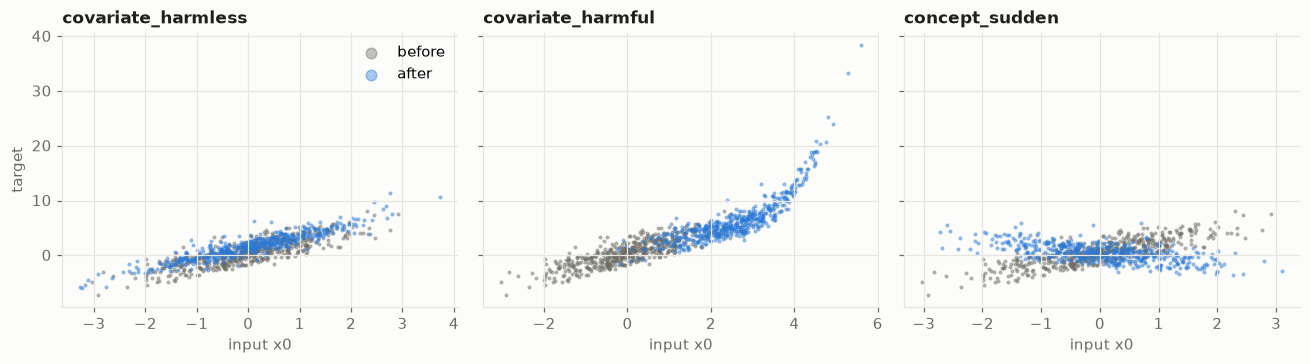

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4), sharey=True)
for ax, sc in zip(axes, ['covariate_harmless', 'covariate_harmful', 'concept_sudden']):
    s = simulate.stream(sc, 0)
    for b, col in ((30, plot.MUTED), (55, plot.SERIES[0])):
        ax.scatter(s.X[b][:, 0], s.y[b], s=3, alpha=0.4, color=col, label='before' if b < 40 else 'after')
    ax.set_title(sc); ax.set_xlabel('input x0')
axes[0].set_ylabel('target'); axes[0].legend(markerscale=4)
plt.tight_layout()

## 2 · A fair comparison: same false-alarm rate for every trigger

A more sensitive trigger catches more and also cries wolf more. So every trigger's threshold is set so
that on *drift-free* streams (50 calibration streams, never reused for testing) it fires in about 1 batch
in 300. The common industry rule "PSI above 0.2" is kept as an extra, uncalibrated row.

In [3]:
pd.Series(json.load(open('results/thresholds.json'))['thresholds']).round(3).rename('calibrated threshold')

psi             0.058
ks              2.435
c2st            0.559
pred_psi        0.053
error           1.089
page_hinkley    0.374
psi_error       1.045
Name: calibrated threshold, dtype: float64

## 3 · The result: 30 streams per scenario

**Total cost** = summed prediction error over the 60 production batches (retrains not yet priced in).
Lower is better. ± = 95% interval over the 30 streams.

In [4]:
def ci(x):
    rng = np.random.default_rng(0); b = rng.choice(x.values, (2000, len(x))).mean(1)
    return (np.percentile(b, 97.5) - np.percentile(b, 2.5)) / 2
order = ['never', 'schedule', 'psi_rule', 'psi', 'ks', 'c2st', 'pred_psi', 'psi_error', 'error', 'page_hinkley',
         'error_cp', 'page_hinkley_cp', 'error_cpw', 'page_hinkley_cpw', 'oracle']
g = t.groupby(['trigger', 'scenario']).error_total
tab = (g.mean().round(1).astype(str) + ' ± ' + g.apply(ci).round(1).astype(str)).unstack().reindex(order)
tab.index = [LABELS[i] for i in tab.index]
tab[list(simulate.SCENARIOS)]

scenario,none,covariate_harmless,covariate_harmful,concept_sudden,concept_gradual,concept_complex
never retrain,25.3 ± 0.1,25.3 ± 0.1,73.1 ± 1.2,105.4 ± 0.3,82.0 ± 0.2,86.6 ± 0.2
every 10 batches,26.0 ± 0.1,25.9 ± 0.1,42.9 ± 0.5,48.9 ± 0.2,46.9 ± 0.1,59.1 ± 2.4
input drift: PSI > 0.2 rule,25.3 ± 0.1,25.7 ± 0.1,37.8 ± 0.5,105.4 ± 0.3,82.0 ± 0.2,86.6 ± 0.2
input drift: PSI,25.3 ± 0.1,25.7 ± 0.1,37.7 ± 0.5,100.6 ± 4.3,79.1 ± 2.6,84.4 ± 2.4
input drift: KS test,25.4 ± 0.1,25.7 ± 0.1,37.8 ± 0.5,96.7 ± 6.4,77.8 ± 3.1,82.2 ± 3.3
input drift: classifier test,25.4 ± 0.1,25.7 ± 0.1,37.9 ± 0.6,102.0 ± 3.5,80.2 ± 2.0,84.5 ± 2.2
prediction drift: PSI,25.3 ± 0.1,25.7 ± 0.1,37.8 ± 0.5,100.9 ± 4.6,80.3 ± 1.7,84.7 ± 2.0
input flag + error confirms,25.3 ± 0.1,25.6 ± 0.1,39.8 ± 0.6,100.6 ± 4.3,79.1 ± 2.6,84.4 ± 2.4
error ratio,25.3 ± 0.1,25.3 ± 0.1,40.6 ± 1.1,62.9 ± 2.4,45.0 ± 0.4,65.1 ± 2.3
Page-Hinkley (error),25.3 ± 0.1,25.3 ± 0.1,39.6 ± 0.6,47.0 ± 0.2,42.7 ± 0.3,61.6 ± 3.1


In [5]:
harm = ['covariate_harmful', 'concept_sudden', 'concept_gradual', 'concept_complex']
h = t[t.scenario.isin(harm)]
summary = pd.DataFrame({
    'concept drift caught (share of streams)': h[h.scenario.str.startswith('concept')].assign(c=lambda x: x.first_retrain_delay.notna() & (x.first_retrain_delay < 15)).groupby('trigger').c.mean(),
    'median batches to first retrain': h.groupby('trigger').first_retrain_delay.median(),
    'wasted retrains per harmless stream': t[t.scenario == 'covariate_harmless'].groupby('trigger').wasted_retrains.mean(),
}).reindex(order).round(2)
summary.index = [LABELS[i] for i in summary.index]
summary

,concept drift caught (share of streams),median batches to first retrain,wasted retrains per harmless stream
never retrain,0.00,NaN,0.00
every 10 batches,1.00,0.0,5.00
input drift: PSI > 0.2 rule,0.00,0.0,3.00
input drift: PSI,0.07,0.0,3.20
input drift: KS test,0.10,0.0,3.07
input drift: classifier test,0.07,0.0,3.10
prediction drift: PSI,0.10,0.0,3.17
input flag + error confirms,0.07,2.0,0.80
error ratio,1.00,2.0,0.10
Page-Hinkley (error),1.00,2.0,0.07


**Reading it:**

- **Input-drift triggers are blind to concept drift.** PSI, KS, the classifier test and prediction
  drift fire on the meaning-changes only at their false-alarm rate (the occasional "catch" 15+ batches
  later is luck). The PSI > 0.2 rule never fires at all.
- **They pay for harmless drift:** about 3 retrains per stream when the inputs moved somewhere the
  model already handled.
- **Error-based triggers catch every harmful change** within 2-5 batches, and almost never retrain for
  nothing. Their catch: they need labels.
- **Where input drift wins:** when inputs move into new territory, it fires instantly (before any labels
  arrive), and is slightly cheaper there (37.7 vs 40.6).

## 4 · Detecting fast isn't enough: retrain on the right data

The plain error trigger notices sudden concept drift within 2 batches, yet costs far more than the
oracle (62.9 vs 38.9). It retrains on the last 10 batches, which are mostly *from before the change*,
so the new model is a blend of the old world and the new one.

**Change-point window:** Page-Hinkley's running sum of excess error has its lowest point just before
the change began. Retraining only on data after that point (and waiting until there is enough of it)
nearly closes the gap: 43.0, with half the retrains. It hurts when inputs move to new territory (47.0
vs 40.6), where the post-change window is too small.

A compromise, the **weighted window**, keeps the full window but counts post-change rows 4 times. It
gives the benefit back (81.5 on sudden concept drift: pre-change rows that now mean the opposite still
pull the model the wrong way). Notebook 3 shows why it was worth trying anyway: on seasonal real data the
short window fails and the weighted one doesn't.

## 5 · Pricing the retrain: which trigger is cheapest?

Each retrain costs a data scientist's time and compute. Expressed in "batches of normal prediction
error", the cheapest trigger on average across all six scenarios:

,0,1,2,5,10,20,40
cheapest trigger,Page-Hinkley + change point,Page-Hinkley + change point,Page-Hinkley + change point,error ratio + change point,error ratio + change point,never retrain,never retrain


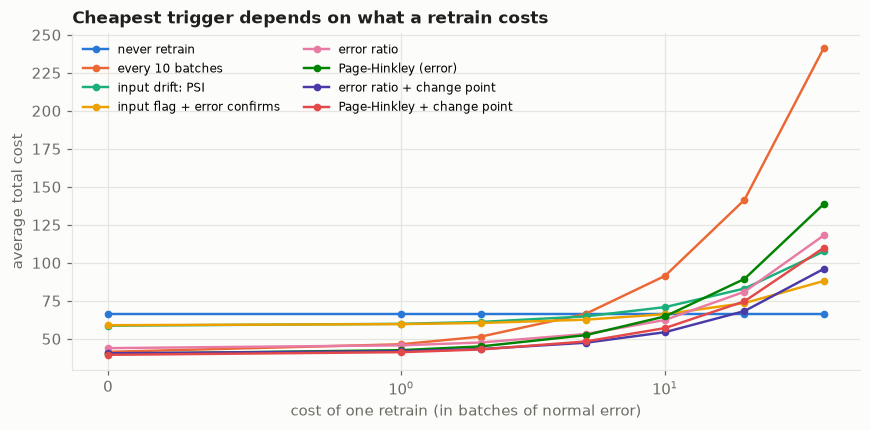

In [6]:
cc = pd.read_csv('results/cost_curve_synthetic.csv', index_col=0)
cc.columns = cc.columns.astype(int)
show = ['never', 'schedule', 'psi', 'psi_error', 'error', 'page_hinkley', 'error_cp', 'page_hinkley_cp']
fig, ax = plt.subplots(figsize=(8, 4))
for k, name in enumerate(show):
    ax.plot(cc.columns, cc.loc[name], marker='o', markersize=4, color=plot.SERIES[k % 8], label=LABELS[name])
ax.set_xscale('symlog', linthresh=1); ax.set_xlabel('cost of one retrain (in batches of normal error)')
ax.set_ylabel('average total cost'); ax.set_title('Cheapest trigger depends on what a retrain costs')
ax.legend(fontsize=8, ncol=2); plt.tight_layout()
best = cc.drop(index='oracle').idxmin().map(LABELS)
best.rename('cheapest trigger').to_frame().T

- **Cheap retrains (0-2):** Page-Hinkley with a change-point window.
- **Moderate (5-10):** error ratio with a change-point window: it retrains less often.
- **Very expensive (20+):** in this simulation, never retraining wins: no change is costly enough
  to pay for the data scientist. In a real business that threshold is a number worth knowing.
- **Input-drift triggers are never the cheapest** here, at any price. (Notebook 3 finds an exception on
  real data: with a stronger, weather-aware model, a multivariate input check wins.)

**What this means in practice:** page on *performance* when labels come back reasonably fast; use input
drift as an early, low-priority flag (and as the only signal when labels never come back); and when you
retrain, train on data from after the change, not a fixed window.

## References

**Textbooks**

- Treveil, M. et al. (2020). *Introducing MLOps*. O'Reilly. Ch. 7, "Monitoring and Feedback Loop": drift causes, KS and chi-squared tests, the domain classifier, pp. 91-95.
- McMahon, A. P. (2023). *Machine Learning Engineering with Python*, 2nd ed. Packt. Ch. 3, "Retraining required" and "Detecting data drift", pp. 97-102.
- Kubat, M. (2017). *An Introduction to Machine Learning*, 2nd ed. Springer. Ch. 10, "Concept drift" and sliding windows over a stream (Fig. 10.3).
- Ameisen, E. (2020). *Building Machine Learning Powered Applications*. O'Reilly. Ch. 11: retraining when a monitored metric drops below a threshold.
- Skiena, S. (2017). *The Data Science Design Manual*. Springer. Sec. 5.3.3, "The Kolmogorov-Smirnov test", pp. 139-140; Sec. 7.4, ROC curves, pp. 218-219.
- Wasserman, L. (2004). *All of Statistics*. Springer. Ch. 8, "The Bootstrap" (percentile intervals), pp. 107-117.
- Kuhn, M. & Johnson, K. (2013). *Applied Predictive Modeling*. Springer. Sec. 8.6, "Boosting", pp. 203-208.
- Müller, A. C. & Guido, S. (2016). *Introduction to Machine Learning with Python*. O'Reilly. Ch. 2: "tree-based regression models are not able to extrapolate" (RAM-price example), pp. 82-84.
- Brownlee, J. (2020). *Introduction to Time Series Forecasting with Python*. Sec. 16.5, "Walk Forward Validation", pp. 151-153.

**Papers, documentation and data**

- Basseville, M. & Nikiforov, I. V. (1993). *Detection of Abrupt Changes: Theory and Application*. Prentice Hall.
- Efron, B. & Tibshirani, R. J. (1993). *An Introduction to the Bootstrap*. Chapman & Hall.
- Friedman, J. H. (2001). Greedy function approximation: a gradient boosting machine. *Annals of Statistics* 29(5), 1189-1232.
- Gama, J., Žliobaitė, I., Bifet, A., Pechenizkiy, M. & Bouchachia, A. (2014). A survey on concept drift adaptation. *ACM Computing Surveys* 46(4), 44.
- Hinkley, D. V. (1971). Inference about the change-point from cumulative sum tests. *Biometrika* 58(3), 509-523.
- Lopez-Paz, D. & Oquab, M. (2017). Revisiting classifier two-sample tests. *ICLR 2017*.
- Lu, J., Liu, A., Dong, F., Gu, F., Gama, J. & Zhang, G. (2019). Learning under concept drift: a review. *IEEE Transactions on Knowledge and Data Engineering* 31(12), 2346-2363.
- Massey, F. J. (1951). The Kolmogorov-Smirnov test for goodness of fit. *Journal of the American Statistical Association* 46(253), 68-78.
- Moreno-Torres, J. G., Raeder, T., Alaiz-Rodríguez, R., Chawla, N. V. & Herrera, F. (2012). A unifying view on dataset shift in classification. *Pattern Recognition* 45(1), 521-530.
- Page, E. S. (1954). Continuous inspection schemes. *Biometrika* 41(1/2), 100-115.
- Quiñonero-Candela, J., Sugiyama, M., Schwaighofer, A. & Lawrence, N. D. (eds.) (2009). *Dataset Shift in Machine Learning*. MIT Press.
- Yurdakul, B. (2018). *Statistical Properties of Population Stability Index*. PhD dissertation, Western Michigan University.